# 04 · Reconocimiento de entidades nombradas

Extracción de entidades del corpus del numeral 1 (`texto_crudo` en `datos/corpus.csv`) con spaCy y el modelo `es_core_news_sm`. Verdad y Falso se procesan por separado. Las tablas y los gráficos se guardan en `resultados/ner/`.

## 0. Configuración

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BASE = Path.cwd()
DATOS = BASE / "datos"
NER = BASE / "resultados" / "ner"
NER.mkdir(parents=True, exist_ok=True)

TIPOS = ["PER", "LOC", "ORG", "MISC"]
SIGNIFICADO = {"PER": "Persona", "LOC": "Lugar", "ORG": "Organización", "MISC": "Otros"}
ENTIDADES_PATH = NER / "entidades.csv"

pd.set_option("display.max_colwidth", 160)

corpus = pd.read_csv(DATOS / "corpus.csv", keep_default_na=False)
print(corpus.shape)
print(corpus["clase"].value_counts().to_string())

(5150, 8)
clase
Verdad    2575
Falso     2575


## 1. Extracción

De cada noticia se guardan el documento, el texto de la entidad, el tipo (`PER`, `LOC`, `ORG` o `MISC`) y la clase. Se desactiva el parser porque esta sección solo usa el reconocedor de entidades. Si `resultados/ner/entidades.csv` ya existe, se carga y no se vuelve a etiquetar.

In [2]:
if ENTIDADES_PATH.exists():
    entidades = pd.read_csv(ENTIDADES_PATH, keep_default_na=False)
    print(f"Cargado {ENTIDADES_PATH.name}: {len(entidades)} entidades")
else:
    import spacy

    nlp = spacy.load("es_core_news_sm")
    nlp.disable_pipes("parser")
    filas = []
    for clase in ["Verdad", "Falso"]:
        parte = corpus.loc[corpus["clase"] == clase, ["doc_id", "texto_crudo"]]
        documentos = nlp.pipe(parte["texto_crudo"].tolist(), batch_size=64)
        for doc_id, doc in zip(parte["doc_id"].tolist(), documentos):
            for ent in doc.ents:
                texto = ent.text.strip()
                if not texto:
                    continue
                filas.append((doc_id, texto, ent.label_, clase))
        print(clase, "etiquetada")
    entidades = pd.DataFrame(filas, columns=["doc_id", "entidad", "tipo", "clase"])
    entidades.to_csv(ENTIDADES_PATH, index=False)
    print(f"Guardado {ENTIDADES_PATH.name}: {len(entidades)} entidades")

doc_id = corpus.loc[0, "doc_id"]
print()
print(doc_id, "·", corpus.loc[0, "clase"])
print(corpus.loc[0, "texto_crudo"])
(
    entidades.loc[entidades["doc_id"] == doc_id, ["doc_id", "entidad", "tipo", "clase"]]
    .rename(columns={"doc_id": "Documento", "entidad": "Entidad", "tipo": "Tipo", "clase": "Clase"})
    .reset_index(drop=True)
)

Cargado entidades.csv: 28604 entidades

curado_2501 · Verdad
El 51% de los alemanes está en contra de la extradición de Puigdemont a España. Una encuesta de diario Die Welt revela que son los votantes de La Izquierda y de la ultraderecha los que más rechazan que el expresident de la Generalitat sea entregado a España, donde se le acusa de rebelión y malversación de fondos públicos


,Documento,Entidad,Tipo,Clase
0,curado_2501,Puigdemont,LOC,Verdad
1,curado_2501,España,PER,Verdad
2,curado_2501,Una encuesta de diario,MISC,Verdad
3,curado_2501,Die Welt,MISC,Verdad
4,curado_2501,La Izquierda,ORG,Verdad
5,curado_2501,Generalitat,LOC,Verdad
6,curado_2501,España,LOC,Verdad


## 2. Total y distribución porcentual

El porcentaje de cada tipo se calcula sobre el total de entidades de esa clase, no sobre las palabras.

In [3]:
conteo = entidades.groupby(["clase", "tipo"]).size()
totales = entidades.groupby("clase").size()

filas = []
for tipo in TIPOS:
    verdad = int(conteo.get(("Verdad", tipo), 0))
    falso = int(conteo.get(("Falso", tipo), 0))
    filas.append({
        "Tipo": tipo,
        "Significado": SIGNIFICADO[tipo],
        "Verdaderas (cantidad)": verdad,
        "Verdaderas (%)": round(verdad / totales["Verdad"] * 100, 2),
        "Falsas (cantidad)": falso,
        "Falsas (%)": round(falso / totales["Falso"] * 100, 2),
    })
distribucion = pd.DataFrame(filas)
distribucion.to_csv(NER / "distribucion.csv", index=False)
print(
    "Entidades: "
    f"Verdad {int(totales['Verdad'])} · Falso {int(totales['Falso'])}"
)
distribucion

Entidades: Verdad 13949 · Falso 14655


,Tipo,Significado,Verdaderas (cantidad),Verdaderas (%),Falsas (cantidad),Falsas (%)
0,PER,Persona,3519,25.23,4348,29.67
1,LOC,Lugar,4106,29.44,4066,27.74
2,ORG,Organización,3285,23.55,3128,21.34
3,MISC,Otros,3039,21.79,3113,21.24


## 3. Gráficos

El primero compara los tipos. Los otros dos muestran las 15 entidades más frecuentes de cada clase; la tabla de la sección 4 guarda las 20.

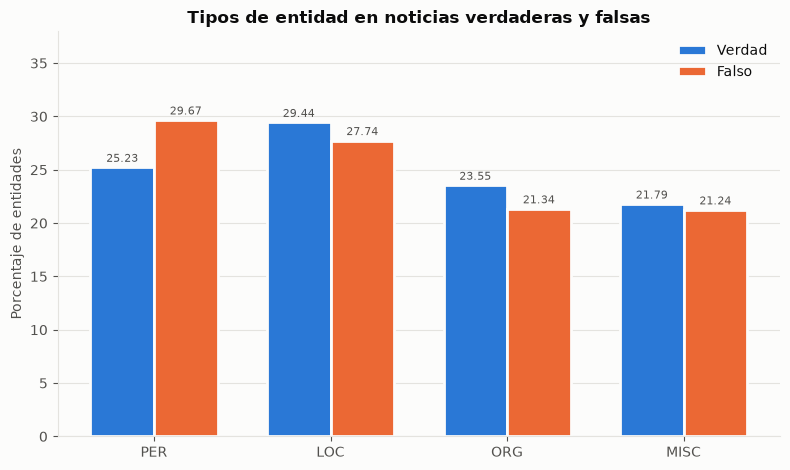

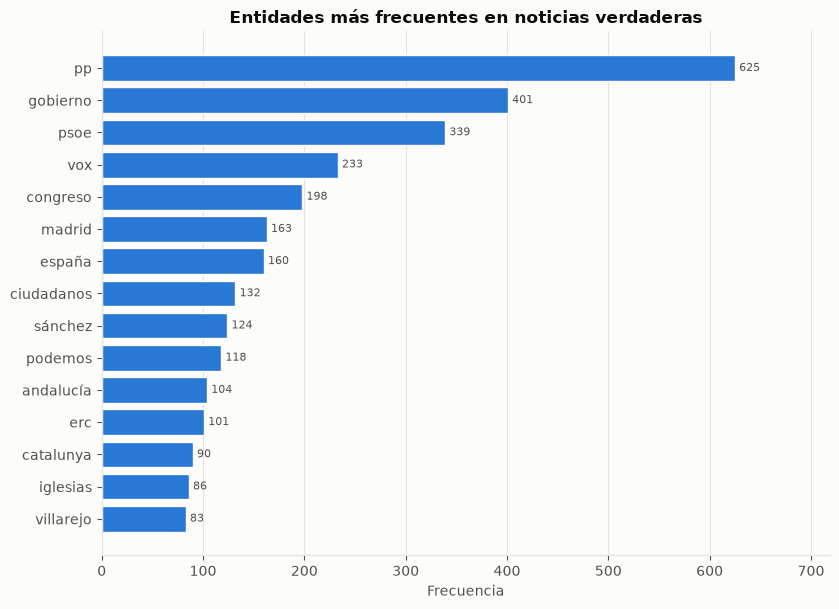

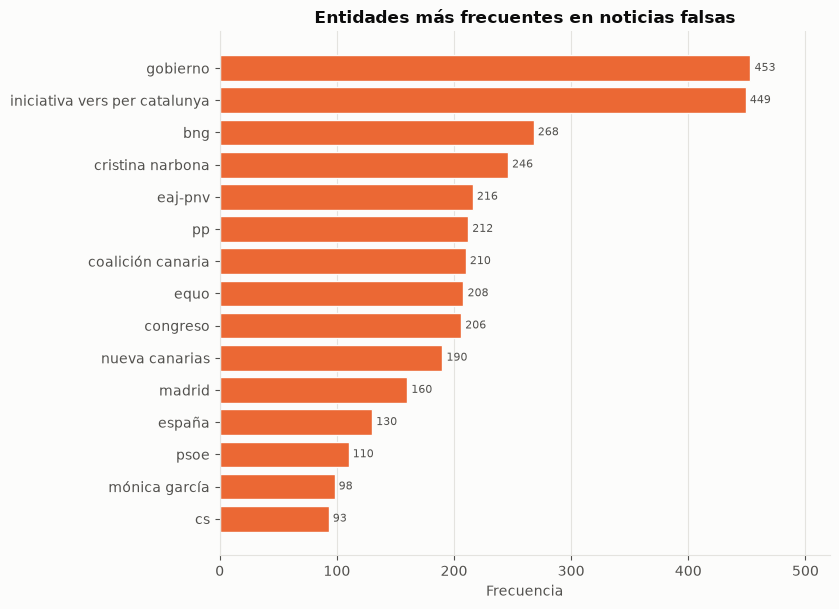

In [4]:
SUPERFICIE, TINTA, TINTA_2, CUADRICULA = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": CUADRICULA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "text.color": TINTA, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": CUADRICULA, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

fig, ax = plt.subplots(figsize=(8, 4.8))
posiciones = np.arange(len(TIPOS))
ancho = 0.36
barras_v = ax.bar(
    posiciones - ancho / 2, distribucion["Verdaderas (%)"], ancho,
    label="Verdad", color="#2a78d6", edgecolor=SUPERFICIE, linewidth=2,
)
barras_f = ax.bar(
    posiciones + ancho / 2, distribucion["Falsas (%)"], ancho,
    label="Falso", color="#eb6834", edgecolor=SUPERFICIE, linewidth=2,
)
ax.bar_label(barras_v, fmt="%.2f", padding=2, fontsize=8, color=TINTA_2)
ax.bar_label(barras_f, fmt="%.2f", padding=2, fontsize=8, color=TINTA_2)
ax.set_xticks(posiciones, TIPOS)
ax.set_ylabel("Porcentaje de entidades")
ax.set_title("Tipos de entidad en noticias verdaderas y falsas")
ax.legend(frameon=False)
ax.set_ylim(0, distribucion[["Verdaderas (%)", "Falsas (%)"]].to_numpy().max() * 1.28)
plt.tight_layout()
plt.savefig(NER / "tipos.png", dpi=150)
plt.show()


def barras_frecuentes(clase, color, ruta):
    serie = (
        entidades.loc[entidades["clase"] == clase, "entidad"]
        .str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .value_counts()
        .head(15)
        .iloc[::-1]
    )
    fig, ax = plt.subplots(figsize=(8.5, 6.2))
    ax.barh(serie.index, serie.values, color=color, edgecolor=SUPERFICIE, linewidth=1)
    ax.bar_label(ax.containers[0], padding=3, fontsize=8, color=TINTA_2)
    ax.set_xlabel("Frecuencia")
    ax.set_xlim(0, serie.max() * 1.15)
    nombre = {"Verdad": "verdaderas", "Falso": "falsas"}[clase]
    ax.set_title(f"Entidades más frecuentes en noticias {nombre}")
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.savefig(ruta, dpi=150)
    plt.show()


barras_frecuentes("Verdad", "#2a78d6", NER / "top_verdad.png")
barras_frecuentes("Falso", "#eb6834", NER / "top_falso.png")

## 4. Entidades más frecuentes

Se agrupa por el texto en minúsculas, así «España» y «españa» cuentan como la misma entidad. Primero, las 10 de cada tipo en cada clase. Después, las 20 de cada clase sin separar por tipo.

In [5]:
from IPython.display import display

entidades = entidades.copy()
entidades["norm"] = entidades["entidad"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()


def ranking(filtro, n):
    return filtro["norm"].value_counts().head(n).rename_axis("entidad").reset_index(name="frecuencia")


bloques = []
for tipo in TIPOS:
    for clase in ["Verdad", "Falso"]:
        parte = ranking(entidades[(entidades["tipo"] == tipo) & (entidades["clase"] == clase)], 10)
        parte.insert(0, "puesto", range(1, len(parte) + 1))
        parte.insert(0, "clase", clase)
        parte.insert(0, "tipo", tipo)
        bloques.append(parte)
top10 = pd.concat(bloques, ignore_index=True)
top10.to_csv(NER / "top10_tipo.csv", index=False)

for tipo in TIPOS:
    verdad = top10.loc[(top10["tipo"] == tipo) & (top10["clase"] == "Verdad"), ["puesto", "entidad", "frecuencia"]]
    falso = top10.loc[(top10["tipo"] == tipo) & (top10["clase"] == "Falso"), ["entidad", "frecuencia"]]
    vista = pd.concat(
        [
            verdad.reset_index(drop=True).rename(columns={"entidad": "Verdad", "frecuencia": "Frecuencia verdad"}),
            falso.reset_index(drop=True).rename(columns={"entidad": "Falso", "frecuencia": "Frecuencia falso"}),
        ],
        axis=1,
    )
    print(tipo, "·", SIGNIFICADO[tipo])
    display(vista)

globales = []
for clase in ["Verdad", "Falso"]:
    parte = ranking(entidades[entidades["clase"] == clase], 20)
    parte.insert(0, "puesto", range(1, len(parte) + 1))
    parte.insert(0, "clase", clase)
    globales.append(parte)
top20 = pd.concat(globales, ignore_index=True)
top20.to_csv(NER / "top20.csv", index=False)

print("Top 20")
display(
    pd.concat(
        [
            top20.loc[top20["clase"] == "Verdad", ["puesto", "entidad", "frecuencia"]]
            .reset_index(drop=True)
            .rename(columns={"entidad": "Verdad", "frecuencia": "Frecuencia verdad"}),
            top20.loc[top20["clase"] == "Falso", ["entidad", "frecuencia"]]
            .reset_index(drop=True)
            .rename(columns={"entidad": "Falso", "frecuencia": "Frecuencia falso"}),
        ],
        axis=1,
    )
)

PER · Persona


,puesto,Verdad,Frecuencia verdad,Falso,Frecuencia falso
0,1,españa,92,cristina narbona,246
1,2,iglesias,86,mónica garcía,98
2,3,pedro sánchez,82,rita maestre,89
3,4,rajoy,52,españa,78
4,5,andalucía,50,boluarte,71
5,6,ayuso,47,pablo echenique,67
6,7,pablo iglesias,47,carlos prieto,60
7,8,sánchez,42,jordi sevilla,53
8,9,franco,42,gallardo,52
9,10,presupuestos,38,juan carlos,49


LOC · Lugar


,puesto,Verdad,Frecuencia verdad,Falso,Frecuencia falso
0,1,gobierno,358,gobierno,402
1,2,madrid,163,coalición canaria,202
2,3,supremo,71,nueva canarias,190
3,4,podemos,70,madrid,160
4,5,villarejo,64,comunidad de madrid,56
5,6,españa,63,andalucía,51
6,7,barcelona,56,españa,49
7,8,estado,56,barcelona,46
8,9,andalucía,51,villarejo,43
9,10,comunidad de madrid,51,estado,41


ORG · Organización


,puesto,Verdad,Frecuencia verdad,Falso,Frecuencia falso
0,1,pp,625,iniciativa vers per catalunya,368
1,2,psoe,339,bng,268
2,3,vox,225,eaj-pnv,216
3,4,congreso,190,pp,212
4,5,ciudadanos,125,congreso,195
5,6,erc,101,equo,181
6,7,unidas podemos,73,psoe,110
7,8,sánchez,45,unidas eaj-pnv,51
8,9,iu,45,unidas pp,49
9,10,senado,43,vox,43


MISC · Otros


,puesto,Verdad,Frecuencia verdad,Falso,Frecuencia falso
0,1,ejecutivo,77,iniciativa vers per catalunya,81
1,2,catalunya,51,ejecutivo,75
2,3,casado,50,cs,69
3,4,fiscalía,38,catalunya,50
4,5,cs,34,jxcat,32
5,6,sánchez,29,el presidente del gobierno,26
6,7,el presidente del gobierno,28,gobierno,24
7,8,podemos,19,fiscalía,23
8,9,junta,17,junta,18
9,10,jxcat,15,el líder del iniciativa vers per catalunya,17


Top 20


,puesto,Verdad,Frecuencia verdad,Falso,Frecuencia falso
0,1,pp,625,gobierno,453
1,2,gobierno,401,iniciativa vers per catalunya,449
2,3,psoe,339,bng,268
3,4,vox,233,cristina narbona,246
4,5,congreso,198,eaj-pnv,216
5,6,madrid,163,pp,212
6,7,españa,160,coalición canaria,210
7,8,ciudadanos,132,equo,208
8,9,sánchez,124,congreso,206
9,10,podemos,118,nueva canarias,190


## 5. Análisis

¿Las noticias falsas y verdaderas presentan diferencias en los tipos o en las entidades concretas que mencionan?

- El volumen es parecido: 13.949 entidades en verdaderas y 14.655 en falsas.
- Los tipos se parecen. La diferencia más grande es `PER`: 25,23 % en verdaderas y 29,67 % en falsas. Lugares, organizaciones y otros quedan a menos de 2,5 puntos.
- Esa comparación hay que leerla con cuidado. «Gobierno» queda casi siempre como `LOC`, y en las falsas el modelo mete en `LOC` a partidos como Coalición Canaria y Nueva Canarias. El porcentaje de lugares está inflado por organizaciones.
- Las entidades concretas sí cambian. En las verdaderas dominan PP (625), PSOE (339), Vox (233) y Podemos (118). En las falsas dominan actores desplazados: Iniciativa vers per Catalunya (449, y ninguna en verdaderas), BNG (268 frente a 10), Cristina Narbona (246 frente a 2), EAJ-PNV (216 frente a 1), Coalición Canaria (210 frente a 6), Equo (208 frente a 5) y Nueva Canarias (190 frente a 5).
- El NER confirma lo que aprendió el clasificador: las falsas fabricadas se distinguen por partidos y políticos fuera de lugar, no por un tipo de entidad distinto.

## 6. Errores del modelo

Cinco casos reales de `es_core_news_sm`. En cada uno está el documento y la frase.

1. **Tipo incorrecto.** En `curado_2501`, «Puigdemont» queda como `LOC`. Es una persona. Frase: «El 51% de los alemanes está en contra de la extradición de Puigdemont a España».
2. **Tipo incorrecto, y distinto en la misma noticia.** En `curado_2501`, la primera «España» queda como `PER` y la segunda como `LOC`. Es un lugar. Frase: «…de Puigdemont a España. […] sea entregado a España, donde se le acusa…».
3. **Tipo incorrecto.** En `curado_2530`, «Podemos» sale primero como `LOC` y después como `PER`. Es un partido (`ORG`). Frase: «El exatleta Roberto Sotomayor será el candidato de Podemos al Ayuntamiento de Madrid en 2023. […] La portavoz de Podemos en la Asamblea, Carolina Alonso…».
4. **Entidad que no lo es, y un nombre que no se ve.** En `curado_2561`, «Discrepancias» se marca como `PER` y «Andalucía» también, aunque es un lugar. «Sánchez», que sí es una persona, no aparece. Frase: «Discrepancias sobre un fondo para la financiación de Andalucía y sintonía sobre energía verde entre Moreno y Sánchez».
5. **Entidades no reconocidas.** En `curado_4698`, «Feijóo» y «Ayuso» no salen. «Casado» sí sale, pero como `MISC` y no como `PER`. Frase: «Feijóo asumirá el liderazgo de un PP que no ha sido capaz de pasar página de la corrupción durante la era Casado. Ayuso reconoció que su hermano cobró 280.000 euros…».